In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install funcy

In [ ]:
!pip install scikit-multilearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.4/89.4 kB 5.5 MB/s eta 0:00:00


In [ ]:
import json
import argparse
import funcy
from sklearn.model_selection import train_test_split
from skmultilearn.model_selection import iterative_train_test_split
import numpy as np
import os
from PIL import Image
from tqdm import tqdm
from pprint import pprint
import json
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [ ]:
annotations_file = "/content/drive/MyDrive/ThesisDataset/annotations/instances.json"

with open(annotations_file, 'r', encoding='utf-8') as file:
    data = json.load(file)

print("Top-level keys in the JSON file:")
pprint(list(data.keys()))

if 'info' in data:
    print("\nInfo Section:")
    pprint(data['info'])

if 'licenses' in data:
    print("\nLicenses Section:")
    pprint(data['licenses'])

if 'images' in data:
    print("\nImages Section (First 5 entries):")
    pprint(data['images'][:5])

if 'annotations' in data:
    print("\nAnnotations Section (First 5 entries):")
    pprint(data['annotations'][:5])

if 'categories' in data:
    print("\nCategories Section:")
    pprint(data['categories'])


Top-level keys in the JSON file:
['info', 'licenses', 'images', 'annotations', 'categories']

Info Section:
{'contributor': 'Supervisely',
 'date_created': '2024-10-03T17:21:06.618Z',
 'description': '',
 'url': 'None',
 'version': '1.0',
 'year': 2024}

Licenses Section:
[{'id': 0, 'name': 'None', 'url': 'None'}]

Images Section (First 5 entries):
[{'date_captured': '2024-10-03T17:21:09.674Z',
  'file_name': '7.jpg',
  'height': 227,
  'id': 344570940,
  'license': 'None',
  'url': 'None',
  'width': 227},
 {'date_captured': '2024-10-03T17:32:15.620Z',
  'file_name': '3609.jpg',
  'height': 227,
  'id': 344573796,
  'license': 'None',
  'url': 'None',
  'width': 227},
 {'date_captured': '2024-10-03T17:32:15.620Z',
  'file_name': '3787.jpg',
  'height': 227,
  'id': 344573797,
  'license': 'None',
  'url': 'None',
  'width': 227},
 {'date_captured': '2024-10-03T17:32:15.620Z',
  'file_name': '3393.jpg',
  'height': 227,
  'id': 344573798,
  'license': 'None',
  'url': 'None',
  'width'

In [ ]:
def merge_and_update_categories(coco_json_path):
    with open(coco_json_path, 'r') as f:
        data = json.load(f)

    slope_streak_id = None
    slope_streak_bbox_id = None

    for category in data['categories']:
        if category['name'] == 'slope_streak':
            slope_streak_id = category['id']
        elif category['name'] == 'slope_streak_bbox':
            slope_streak_bbox_id = category['id']

    for annotation in data['annotations']:
        if annotation['category_id'] == slope_streak_bbox_id:
            annotation['category_id'] = slope_streak_id

    data['categories'] = [category for category in data['categories'] if category['id'] != slope_streak_bbox_id]

    for category in data['categories']:
        if category['name'].endswith('_bbox'):
            category['name'] = category['name'].replace('_bbox', '')

    with open(coco_json_path, 'w') as f:
        json.dump(data, f, indent=4)

In [ ]:
merge_and_update_categories(annotations_file)

In [ ]:
with open(annotations_file, 'r', encoding='utf-8') as file:
    data = json.load(file)

In [ ]:
if 'categories' in data:
    print("\nCategories Section:")
    pprint(data['categories'])


Categories Section:
[{'id': 1, 'name': 'spider', 'supercategory': 'spider'},
 {'id': 2, 'name': 'swiss_cheese', 'supercategory': 'swiss_cheese'},
 {'id': 5, 'name': 'crater', 'supercategory': 'crater'},
 {'id': 12, 'name': 'BrightDune', 'supercategory': 'BrightDune_bbox'},
 {'id': 14, 'name': 'DarkDune', 'supercategory': 'DarkDune_bbox'},
 {'id': 16, 'name': 'Impact_Ejecta', 'supercategory': 'Impact_Ejecta_bbox'},
 {'id': 19, 'name': 'slope_streak', 'supercategory': 'slope_streak'}]


In [ ]:
import json

def count_bounding_boxes(coco_json_path):
    with open(coco_json_path, 'r') as f:
        data = json.load(f)

    category_id_to_name = {category['id']: category['name'] for category in data['categories']}

    bbox_count = {}
    for annotation in data['annotations']:
        category_id = annotation['category_id']

        category_name = category_id_to_name.get(category_id, None)

        if category_name:
            if category_name not in bbox_count:
                bbox_count[category_name] = 0
            bbox_count[category_name] += 1
        else:
            print(f"Warning: Category ID {category_id} not found in categories")

    return bbox_count

bbox_counts = count_bounding_boxes(annotations_file)

for category, count in bbox_counts.items():
    print(f"{category}: {count} bounding boxes")

slope_streak: 818 bounding boxes
spider: 319 bounding boxes
swiss_cheese: 592 bounding boxes
crater: 1493 bounding boxes
BrightDune: 1591 bounding boxes
Impact_Ejecta: 50 bounding boxes
DarkDune: 384 bounding boxes


In [ ]:
def resize_images_and_boxes_coco(image_folder, json_path, output_image_folder, output_json_path, target_size=(224, 224)):
    os.makedirs(output_image_folder, exist_ok=True)

    with open(json_path, 'r') as f:
        coco_data = json.load(f)

    images = coco_data['images']
    annotations = coco_data['annotations']

    annotations_by_image = {}
    for ann in annotations:
        annotations_by_image.setdefault(ann['image_id'], []).append(ann)

    for image_info in images:
        image_id = image_info['id']
        file_name = image_info['file_name']
        original_width = image_info['width']
        original_height = image_info['height']

        image_path = os.path.join(image_folder, file_name)
        if not os.path.exists(image_path):
            print(f"Image {file_name} not found. Skipping.")
            continue
        image = Image.open(image_path)
        resized_image = image.resize(target_size)
        resized_image_path = os.path.join(output_image_folder, file_name)
        resized_image.save(resized_image_path)

        x_scale = target_size[0] / original_width
        y_scale = target_size[1] / original_height

        if image_id in annotations_by_image:
            for ann in annotations_by_image[image_id]:
                x, y, width, height = ann['bbox']
                ann['bbox'] = [
                    x * x_scale,
                    y * y_scale,
                    width * x_scale,
                    height * y_scale
                ]

        image_info['width'], image_info['height'] = target_size
    with open(output_json_path, 'w') as f:
        json.dump(coco_data, f, indent=4)

    print(f"Processed all images and saved updated JSON to {output_json_path}.")


In [ ]:
resize_images_and_boxes_coco(
    image_folder = '/content/drive/MyDrive/ThesisDataset/images',
    json_path = annotations_file,
    output_image_folder='/content/drive/MyDrive/ThesisDataset/Rescaled_Data/images',
    output_json_path='/content/drive/MyDrive/ThesisDataset/Rescaled_Data/annotations.json'
)

Processed all images and saved updated JSON to /content/drive/MyDrive/ThesisDataset/Rescaled_Data/annotations.json.


In [ ]:
def count_images(folder_path, extensions=('jpg', 'jpeg', 'png', 'bmp', 'tiff')):
    # Ensure the folder exists
    if not os.path.exists(folder_path):
        print(f"Error: The folder {folder_path} does not exist.")
        return 0

    # Count the image files
    image_count = sum(1 for file in os.listdir(folder_path)
                      if file.lower().endswith(extensions))

    print(f"The folder '{folder_path}' contains {image_count} image file(s).")
    return image_count

rescaled_images_path = '/content/drive/MyDrive/ThesisDataset/Rescaled_Data/images'
count_images(rescaled_images_path)


The folder '/content/drive/MyDrive/ThesisDataset/Rescaled_Data/images' contains 2546 image file(s).


2546

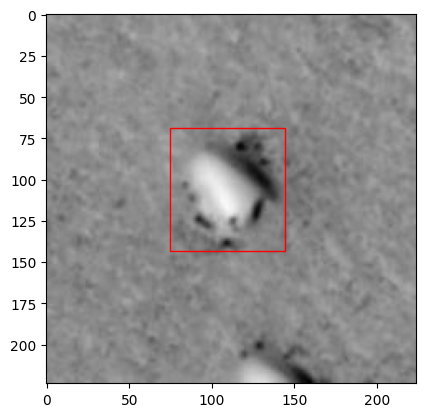

In [ ]:
def visualize_bboxes(image_path, json_path):
    if not os.path.exists(image_path):
        print(f"Error: The image file at {image_path} does not exist.")
        return

    if not os.path.exists(json_path):
        print(f"Error: The JSON file at {json_path} does not exist.")
        return

    with open(json_path, 'r') as f:
        coco_data = json.load(f)

    image = cv2.imread(image_path)
    if image is None:
        print(f"Error: Unable to read the image file at {image_path}.")
        return
    image_name = os.path.basename(image_path)
    image_info = next((img for img in coco_data['images'] if img['file_name'] == image_name), None)

    if not image_info:
        print(f"Error: Image {image_name} not found in the JSON file.")
        return

    image_id = image_info['id']
    bboxes = [ann['bbox'] for ann in coco_data['annotations'] if ann['image_id'] == image_id]

    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax = plt.gca()
    for bbox in bboxes:
        x_min, y_min, width, height = bbox
        rect = Rectangle((x_min, y_min), width, height, linewidth=1, edgecolor='r', facecolor='none')
        ax.add_patch(rect)

    plt.show()

image_path = '/content/drive/MyDrive/ThesisDataset/Rescaled_Data/images/3171_jpg.rf.72244c42434c79faebacdb054bae9d3a.jpg'
json_path = '/content/drive/MyDrive/ThesisDataset/Rescaled_Data/annotations.json'

visualize_bboxes(image_path, json_path)


In [ ]:
bbox_counts = count_bounding_boxes(json_path)

for category, count in bbox_counts.items():
    print(f"{category}: {count} bounding boxes")

slope_streak: 818 bounding boxes
spider: 319 bounding boxes
swiss_cheese: 592 bounding boxes
crater: 1493 bounding boxes
BrightDune: 1591 bounding boxes
Impact_Ejecta: 50 bounding boxes
DarkDune: 384 bounding boxes


In [ ]:
def save_coco(file, info, licenses, images, annotations, categories):
    with open(file, 'wt', encoding='UTF-8') as coco:
        json.dump({
            'info': info,
            'licenses': licenses,
            'images': images,
            'annotations': annotations,
            'categories': categories
        }, coco, indent=2, sort_keys=True)


def filter_annotations(annotations, images):
    image_ids = funcy.lmap(lambda i: int(i['id']), images)
    return funcy.lfilter(lambda a: int(a['image_id']) in image_ids, annotations)


def filter_images(images, annotations):
    annotation_ids = funcy.lmap(lambda i: int(i['image_id']), annotations)
    return funcy.lfilter(lambda a: int(a['id']) in annotation_ids, images)


# images_folder = "/content/drive/MyDrive/ThesisDataset/images"
# annotations_file = "/content/drive/MyDrive/ThesisDataset/annotations/instances.json"
output_folder = "/content/drive/MyDrive/ThesisDataset/Splits"

os.makedirs(output_folder, exist_ok=True)

train_split = 0.7
val_split = 0.1
test_split = 0.2

with open(json_path, 'rt', encoding='UTF-8') as annotations:
    coco = json.load(annotations)
    info = coco['info']
    licenses = coco['licenses']
    images = coco['images']
    annotations = coco['annotations']
    categories = coco['categories']

images_with_annotations = funcy.lmap(lambda a: int(a['image_id']), annotations)
images = funcy.lremove(lambda i: i['id'] not in images_with_annotations, images)

annotation_categories = funcy.lmap(lambda a: int(a['category_id']), annotations)
annotation_categories = funcy.lremove(lambda i: annotation_categories.count(i) <= 1, annotation_categories)
annotations = funcy.lremove(lambda i: i['category_id'] not in annotation_categories, annotations)

train_val_images, test_images = train_test_split(images, train_size=train_split + val_split, random_state=42)
train_images, val_images = train_test_split(train_val_images, train_size=train_split / (train_split + val_split), random_state=42)

anns_train = filter_annotations(annotations, train_images)
anns_val = filter_annotations(annotations, val_images)
anns_test = filter_annotations(annotations, test_images)

save_coco(os.path.join(output_folder, "train.json"), info, licenses, train_images, anns_train, categories)
save_coco(os.path.join(output_folder, "val.json"), info, licenses, val_images, anns_val, categories)
save_coco(os.path.join(output_folder, "test.json"), info, licenses, test_images, anns_test, categories)

print(f"Train: {len(train_images)} images, {len(anns_train)} annotations")
print(f"Validation: {len(val_images)} images, {len(anns_val)} annotations")
print(f"Test: {len(test_images)} images, {len(anns_test)} annotations")

Train: 1781 images, 3634 annotations
Validation: 255 images, 548 annotations
Test: 510 images, 1065 annotations


In [ ]:
#splited_annotation_folder = "/content/drive/MyDrive/ThesisDataset/Splits"
images_data_path = "/content/drive/MyDrive/ThesisDataset/Rescaled_Data/images"
split_folder = "/content/drive/MyDrive/ThesisDataset/Splits"

In [ ]:
def create_splits_folder(output_folder):
    """
    Creates a folder structure with 'train', 'val', and 'test' folders.
    """
    train_folder = os.path.join(split_folder, "train")
    val_folder = os.path.join(split_folder, "val")
    test_folder = os.path.join(split_folder, "test")

    os.makedirs(train_folder, exist_ok=True)
    os.makedirs(val_folder, exist_ok=True)
    os.makedirs(test_folder, exist_ok=True)

    return train_folder, val_folder, test_folder

In [ ]:
def process_images(json_file, images_folder, output_folder):
    """
    Reads the JSON file, moves images corresponding to the IDs in the JSON to the output folder,
    and normalizes them.
    """
    with open(json_file, "r") as file:
        data = json.load(file)
        image_annotations = data["images"]

    print(f"Processing images for {os.path.basename(json_file)}...")

    for image_info in tqdm(image_annotations, desc="Processing images"):
        image_id = image_info["id"]
        file_name = image_info["file_name"]
        src_image_path = os.path.join(images_folder, file_name)

        if not os.path.exists(src_image_path):
            print(f"Warning: {src_image_path} does not exist. Skipping...")
            continue

        try:
            img = Image.open(src_image_path)
            if img.mode != 'L':
                img = img.convert('L')
            output_image_path = os.path.join(output_folder, file_name)
            img.save(output_image_path)
        except Exception as e:
            print(f"Error processing {src_image_path}: {e}")

In [ ]:
train, val, test = create_splits_folder(split_folder)

train_json = os.path.join(split_folder, "train.json")
val_json = os.path.join(split_folder, "val.json")
test_json = os.path.join(split_folder, "test.json")

process_images(train_json, images_data_path, train)
process_images(val_json, images_data_path, val)
process_images(test_json, images_data_path, test)

print("Processing completed.")

Processing images for train.json...


Processing images: 100%|██████████| 1781/1781 [01:36<00:00, 18.49it/s]


Processing images for val.json...


Processing images: 100%|██████████| 255/255 [00:06<00:00, 37.73it/s]


Processing images for test.json...


Processing images: 100%|██████████| 510/510 [00:13<00:00, 38.15it/s]

Processing completed.


In [ ]:
import os
from PIL import Image

def verify_image_sizes(folder_path, target_size=(224, 224)):
    if not os.path.exists(folder_path):
        print(f"Error: The folder {folder_path} does not exist.")
        return

    mismatched_images = []

    for file in os.listdir(folder_path):
        file_path = os.path.join(folder_path, file)
        try:
            with Image.open(file_path) as img:
                if img.size != target_size:
                    mismatched_images.append(file)
        except Exception as e:
            print(f"Error processing file {file}: {e}")

    # Display results
    if mismatched_images:
        print(f"The following images do not have the size {target_size}:")
        for img in mismatched_images:
            print(img)
    else:
        print(f"All images in '{folder_path}' have the size {target_size}.")

folder_path = '/content/drive/MyDrive/ThesisDataset/Splits/train'
verify_image_sizes(folder_path)

All images in '/content/drive/MyDrive/ThesisDataset/Splits/train' have the size (224, 224).


In [ ]:
test_images_path = '/content/drive/MyDrive/ThesisDataset/Splits/test'
verify_image_sizes(test_images_path)

All images in '/content/drive/MyDrive/ThesisDataset/Splits/test' have the size (224, 224).
